In [1]:
import numpy as np
import pygad
import time
import matplotlib.pyplot as plt
from inventory_model import *

def decode(genes):
    m = np.clip(np.array(genes), 0, 1.5).reshape(N, W)
    return m * weekly_fc

def fitness_func(ga_instance, solution, solution_idx):
    return fitness(decode(solution))

baseline = BUDGET_FACTOR * weekly_fc
print("Baseline training fitness:", round(fitness(baseline)))

Baseline training fitness: 749327


In [2]:
POP = 80
rng = np.random.default_rng(42)

init_pop = rng.uniform(0, 1.5, size=(POP, N * W))                       # all random first
init_pop[:60] = np.clip(BUDGET_FACTOR + rng.normal(0, 0.05, size=(60, N * W)), 0, 1.5)  # 60 near baseline
init_pop[0, :] = BUDGET_FACTOR                                           # one exact baseline copy
print(init_pop.shape)

(80, 200)


In [3]:
def on_generation(ga):
    g = ga.generations_completed
    if g % 50 == 0:
        print(f"Generation {g}: best fitness = {ga.best_solution()[1]:,.0f}")

ga2 = pygad.GA(
    num_generations=500,
    num_parents_mating=40,
    initial_population=init_pop,
    fitness_func=fitness_func,
    gene_type=float,
    parent_selection_type="tournament",
    K_tournament=3,
    crossover_type="uniform",
    mutation_type="random",
    mutation_percent_genes=15,
    mutation_by_replacement=False,
    random_mutation_min_val=-0.03,
    random_mutation_max_val=0.03,
    keep_elitism=2,
    random_seed=42,
    on_generation=on_generation,
)

start = time.time()
ga2.run()
print(f"Done in {(time.time() - start) / 60:.1f} minutes")

Generation 50: best fitness = 750,897
Generation 100: best fitness = 751,907
Generation 150: best fitness = 752,197
Generation 200: best fitness = 752,209
Generation 250: best fitness = 752,233
Generation 300: best fitness = 752,369
Generation 350: best fitness = 752,369
Generation 400: best fitness = 752,400
Generation 450: best fitness = 752,466
Generation 500: best fitness = 752,466
Done in 8.7 minutes


In [4]:
solution, best_fit, _ = ga2.best_solution()
plan2 = decode(solution)

def report(name, p):
    v = simulate_profit(p, val_scen)
    a = simulate_profit(p, actual)[0]
    print(f"{name:11s} | train {fitness(p):>9,.0f} | validation mean {v.mean():>9,.0f} "
          f"| 5th pct {np.percentile(v, 5):>9,.0f} | real 2017 {a:>9,.0f} | penalty {penalty(p):.0f}")

report("Baseline", baseline)
report("Seeded GA", plan2)

gain_val = simulate_profit(plan2, val_scen).mean() / simulate_profit(baseline, val_scen).mean() - 1
print(f"\nImprovement on unseen validation scenarios: {gain_val:.2%}")

Baseline    | train   749,327 | validation mean   749,270 | 5th pct   746,321 | real 2017   751,888 | penalty 0
Seeded GA   | train   752,466 | validation mean   752,400 | 5th pct   750,325 | real 2017   753,187 | penalty 0

Improvement on unseen validation scenarios: 0.42%


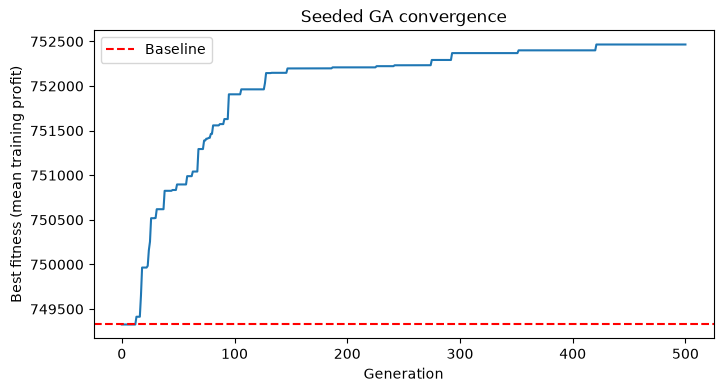

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(ga2.best_solutions_fitness)
plt.axhline(fitness(baseline), color="red", linestyle="--", label="Baseline")
plt.xlabel("Generation")
plt.ylabel("Best fitness (mean training profit)")
plt.title("Seeded GA convergence")
plt.legend()
plt.show()

np.save("best_plan_seeded.npy", plan2)